# Imports & Setup


In [1]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import copy
import hashlib
import json
import random
import time
from pathlib import Path

import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from scipy.stats import sem
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torch_geometric.nn import GATConv, global_mean_pool

torch.set_num_threads(4)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def save_json(path, value):
    path.write_text(json.dumps(value, indent=2), encoding='utf-8')

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def sync():
    if device.type == 'cuda':
        torch.cuda.synchronize()


# Config


In [2]:
variant = 'mean'
artifact_root = Path(r'D:\EEG Experiment Artifacts\2026-11-02')
experiment_root = artifact_root / 'controlled9'
run_dir = experiment_root / variant
run_dir.mkdir(parents=True, exist_ok=True)
signal_path = artifact_root / 'cache/raw_windows_30ch.npy'
meta_path = artifact_root / 'cache/labels8.npz'

run_training = True
seed = 42
epochs = 10
batch_size = 16
learning_rate = 0.001
num_classes = 9
class_names = ['Anger', 'Disgust', 'Fear', 'Sadness', 'Neutral',
               'Amusement', 'Inspiration', 'Joy', 'Tenderness']
channels = ['Fp1','Fp2','Fz','F3','F4','F7','F8','FC1','FC2','FC5','FC6',
            'Cz','C3','C4','T7','T8','CP1','CP2','CP5','CP6','Pz','P3','P4',
            'P7','P8','PO3','PO4','Oz','O1','O2']

settings = {
    'seed': seed, 'epochs': epochs, 'batch_size': batch_size,
    'learning_rate': learning_rate, 'classes': class_names, 'channels': channels,
    'outer_folds': 10, 'inner_validation_fraction': 0.2,
    'evaluation': 'one prediction per second, 30 seconds per trial',
    'labels': 'fixed FACED video categories, not self-ratings',
    'preprocessing': 'official processed EEG; per-trial/channel temporal z-score',
    'graph': 'colin27_1020, distance < 0.15 m, no explicit self-edges; GAT adds self-loops',
    'selection': 'best validation balanced accuracy over 10 epochs',
    'cuda_scatter_may_be_nondeterministic': True
}
print('Variant:', variant, '| Device:', device)
print('Nine stimulus classes; ten subject folds; subject-disjoint inner validation.')
print('Both variants use identical inputs, splits, epochs, and shared-layer initialization.')
print('The encoder and required input projection differ; parameter counts are reported.')
print('Temporal z-scoring uses the full individual trial; this is an offline evaluation.')


Variant: mean | Device: cuda
Nine stimulus classes; ten subject folds; subject-disjoint inner validation.
Both variants use identical inputs, splits, epochs, and shared-layer initialization.
The encoder and required input projection differ; parameter counts are reported.
Temporal z-scoring uses the full individual trial; this is an offline evaluation.


# Load & Preprocess & Split Data


In [3]:
assert signal_path.is_file(), 'The prepared waveform cache is required.'
signals = np.load(signal_path, mmap_mode='r')
meta = np.load(meta_path)
subjects = np.repeat(np.arange(123), 28)
videos = np.tile(np.arange(1, 29), 123)
assert signals.shape == (3444, 30, 30, 250)
assert np.array_equal(meta['subjects'], subjects)
assert np.array_equal(meta['videos'], videos)
video_labels = np.repeat(np.arange(9), [3,3,3,3,4,3,3,3,3])
labels = np.tile(video_labels, 123)

splits = []
for fold in range(10):
    test = np.arange(12 * fold, 12 * (fold + 1) if fold < 9 else 123)
    remaining = np.setdiff1d(np.arange(123), test)
    shuffled = np.random.default_rng(seed + fold).permutation(remaining)
    n_val = round(0.2 * len(remaining))
    val = np.sort(shuffled[:n_val])
    train = np.sort(shuffled[n_val:])
    assert not (set(train) & set(val) or set(train) & set(test) or set(val) & set(test))
    splits.append({'fold': fold, 'train': train.tolist(), 'val': val.tolist(), 'test': test.tolist()})
assert sorted(s for f in splits for s in f['test']) == list(range(123))

protocol_path = experiment_root / 'protocol.json'
if protocol_path.exists():
    protocol = json.loads(protocol_path.read_text())
    assert protocol['settings'] == settings and protocol['splits'] == splits
    assert protocol['cache_size'] == signal_path.stat().st_size
else:
    digest = hashlib.sha256()
    with signal_path.open('rb') as f:
        for chunk in iter(lambda: f.read(4 * 1024 * 1024), b''):
            digest.update(chunk)
    protocol = {'settings': settings, 'splits': splits,
                'cache_sha256': digest.hexdigest(), 'cache_size': signal_path.stat().st_size,
                'cache_source': str(signal_path), 'created_at': time.strftime('%Y-%m-%dT%H:%M:%S')}
    save_json(protocol_path, protocol)
protocol_hash = hashlib.sha256(json.dumps(protocol, sort_keys=True).encode()).hexdigest()

positions = mne.channels.make_standard_montage('colin27_1020').get_positions()['ch_pos']
positions = np.stack([positions[c] for c in channels])
adjacency = cdist(positions, positions) < 0.15
np.fill_diagonal(adjacency, False)
edge_index = torch.tensor(np.array(adjacency.nonzero()), dtype=torch.long)

class Trials(Dataset):
    def __init__(self, indices):
        self.indices = np.asarray(indices)
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, index):
        j = self.indices[index]
        return torch.from_numpy(signals[j].copy()), int(labels[j])

def trial_indices(people):
    return np.flatnonzero(np.isin(subjects, people))

def make_loader(indices, shuffle=False, loader_seed=42):
    return DataLoader(Trials(indices), batch_size=batch_size, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(loader_seed), num_workers=0,
                      pin_memory=device.type == 'cuda')

print('Trials:', len(labels), '| One-second targets:', len(labels) * 30)
print('Graph:', len(channels), 'channels,', edge_index.shape[1], 'directed edges')
print('Outer test subjects per fold:', [len(s['test']) for s in splits])


Trials: 3444 | One-second targets: 103320
Graph: 30 channels, 602 directed edges
Outer test subjects per fold: [12, 12, 12, 12, 12, 12, 12, 12, 12, 15]


# GAT + LSTM Model


In [4]:
class ChannelEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(1, 8, 15, stride=5, padding=7), nn.GELU(),
            nn.Conv1d(8, 16, 7, stride=2, padding=3), nn.GELU(),
            nn.AdaptiveAvgPool1d(8), nn.Flatten(), nn.Linear(128, 32), nn.LayerNorm(32))
    def forward(self, x):
        return self.net(x)

class GATLSTM(nn.Module):
    def __init__(self, variant, init_seed):
        super().__init__()
        self.variant = variant
        with torch.random.fork_rng():
            torch.manual_seed(init_seed + 1000)
            self.encoder = ChannelEncoder() if variant == 'embedding32' else None
            torch.manual_seed(init_seed + 2000)
            self.gat1 = GATConv(32 if self.encoder is not None else 1, 16, heads=4, dropout=0.2)
            torch.manual_seed(init_seed + 3000)
            self.gat2 = GATConv(64, 16, heads=1, dropout=0.2)
            torch.manual_seed(init_seed + 4000)
            self.lstm = nn.LSTM(16, 64, batch_first=True)
            torch.manual_seed(init_seed + 5000)
            self.fc = nn.Linear(64, 9)
        self.register_buffer('base_edges', edge_index.clone())
        self.graph_cache = {}

    def forward(self, x):
        b, t, n, samples = x.shape
        if self.encoder is None:
            h = x.mean(dim=-1).reshape(b * t * n, 1)
        else:
            h = self.encoder(x.reshape(b * t * n, 1, samples))
        count = b * t
        key = (count, x.device)
        if key not in self.graph_cache:
            offsets = torch.arange(count, device=x.device) * n
            edges = (self.base_edges[:, None, :] + offsets[None, :, None]).reshape(2, -1)
            membership = torch.arange(count, device=x.device).repeat_interleave(n)
            self.graph_cache[key] = edges, membership
        edges, membership = self.graph_cache[key]
        h = F.elu(self.gat1(h, edges))
        h = F.elu(self.gat2(h, edges))
        h = global_mean_pool(h, membership, size=count).reshape(b, t, 16)
        h, _ = self.lstm(h)
        return self.fc(h)

probe_model = GATLSTM(variant, seed)
parameter_count = sum(p.numel() for p in probe_model.parameters())
print(probe_model)
print('Trainable parameters:', parameter_count)
del probe_model


GATLSTM(
  (gat1): GATConv(1, 16, heads=4)
  (gat2): GATConv(64, 16, heads=1)
  (lstm): LSTM(16, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=9, bias=True)
)
Trainable parameters: 22905


# Training and Evaluation


In [5]:
def metrics_from_cm(cm):
    cm = np.asarray(cm, dtype=np.float64)
    true = cm.sum(axis=1)
    predicted = cm.sum(axis=0)
    diagonal = np.diag(cm)
    return {'accuracy': float(diagonal.sum() / cm.sum()),
            'balanced_accuracy': float(np.mean(diagonal / np.maximum(true, 1))),
            'macro_f1': float(np.mean(2 * diagonal / np.maximum(true + predicted, 1)))}

def pass_epoch(model, loader, optimizer=None, collect=False):
    training = optimizer is not None
    model.train(training)
    cm = torch.zeros(81, device=device, dtype=torch.long)
    loss_sum, total = 0.0, 0
    predictions, logits_list = [], []
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            target = y[:, None].expand(-1, x.shape[1])
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = F.cross_entropy(logits.reshape(-1, 9), target.reshape(-1))
            if not torch.isfinite(loss):
                raise FloatingPointError('Nonfinite loss')
            if training:
                loss.backward()
                norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                if not torch.isfinite(norm):
                    raise FloatingPointError('Nonfinite gradient')
                optimizer.step()
            predicted = logits.argmax(dim=-1)
            cm += torch.bincount((target * 9 + predicted).reshape(-1), minlength=81)
            total += target.numel()
            loss_sum += loss.item() * target.numel()
            if collect:
                predictions.append(predicted.cpu().numpy())
                logits_list.append(logits.cpu().numpy())
    matrix = cm.reshape(9, 9).cpu().numpy()
    result = {'loss': loss_sum / total, **metrics_from_cm(matrix)}
    return result, matrix, (np.concatenate(predictions) if collect else None), (np.concatenate(logits_list) if collect else None)

def run_fold(split):
    fold = split['fold']
    folder = run_dir / f'fold_{fold:02d}'
    folder.mkdir(exist_ok=True)
    manifest = {'protocol_hash': protocol_hash, 'variant': variant, 'fold': fold,
                'parameters': parameter_count, 'settings': settings,
                'torch': torch.__version__, 'mne': mne.__version__,
                'gpu': torch.cuda.get_device_name(0) if device.type == 'cuda' else None}
    config_path = folder / 'config.json'
    if config_path.exists():
        existing = json.loads(config_path.read_text())
        for key in ['protocol_hash', 'variant', 'fold', 'parameters', 'settings']:
            assert existing[key] == manifest[key], f'Run configuration changed: {key}'
    else:
        save_json(config_path, manifest)
    if (folder / 'metrics.json').exists():
        assert (folder / 'predictions.npz').exists() and (folder / 'best_model.pt').exists()
        print('Restored completed fold', fold, flush=True)
        return json.loads((folder / 'metrics.json').read_text())

    train_idx, val_idx, test_idx = [trial_indices(split[k]) for k in ['train', 'val', 'test']]
    np.savez(folder / 'split_indices.npz', train=train_idx, val=val_idx, test=test_idx)
    seed_all(seed + fold)
    train_loader = make_loader(train_idx, True, seed + fold)
    val_loader = make_loader(val_idx)
    model = GATLSTM(variant, seed + fold).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history, best_score = [], -1.0
    started = time.perf_counter()
    for epoch in range(1, epochs + 1):
        epoch_start = time.perf_counter()
        train_metrics, _, _, _ = pass_epoch(model, train_loader, optimizer)
        val_metrics, _, _, _ = pass_epoch(model, val_loader)
        row = {'epoch': epoch, 'seconds': time.perf_counter() - epoch_start,
               **{'train_' + k: v for k, v in train_metrics.items()},
               **{'val_' + k: v for k, v in val_metrics.items()}}
        history.append(row)
        pd.DataFrame(history).to_csv(folder / 'history.csv', index=False)
        if val_metrics['balanced_accuracy'] > best_score:
            best_score = val_metrics['balanced_accuracy']
            torch.save({'state_dict': model.state_dict(), 'epoch': epoch,
                        'validation': val_metrics, 'config': manifest}, folder / 'best_model.pt')
        print(f"{variant} fold {fold} epoch {epoch}/{epochs}: train={train_metrics['accuracy']:.4f}, val BAcc={val_metrics['balanced_accuracy']:.4f}", flush=True)

    checkpoint = torch.load(folder / 'best_model.pt', map_location=device, weights_only=False)
    model.load_state_dict(checkpoint['state_dict'])
    # The outer test set is first evaluated after selecting the validation checkpoint.
    test_metrics, matrix, predicted, logits = pass_epoch(model, make_loader(test_idx), collect=True)
    target = np.repeat(labels[test_idx, None], 30, axis=1)
    np.savez_compressed(folder / 'predictions.npz', predictions=predicted, logits=logits,
                        labels=target, subjects=subjects[test_idx], videos=videos[test_idx])
    np.savetxt(folder / 'confusion_matrix.csv', matrix, fmt='%d', delimiter=',')
    result = {'fold': fold, 'test_subjects': split['test'], 'best_epoch': checkpoint['epoch'],
              'validation': checkpoint['validation'], 'test': test_metrics,
              'seconds': time.perf_counter() - started}
    save_json(folder / 'metrics.json', result)
    print('FOLD COMPLETE', json.dumps(result), flush=True)
    del model, optimizer
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    return result

def summarize():
    predictions = np.full((123, 28, 30), -1, dtype=np.int64)
    fold_results = []
    for split in splits:
        folder = run_dir / f"fold_{split['fold']:02d}"
        result = json.loads((folder / 'metrics.json').read_text())
        fold_results.append(result)
        saved = np.load(folder / 'predictions.npz')
        for sub in split['test']:
            mask = saved['subjects'] == sub
            assert np.array_equal(saved['videos'][mask], np.arange(1, 29))
            assert mask.sum() == 28
            predictions[sub] = saved['predictions'][mask]
    target = np.tile(np.repeat(video_labels[:, None], 30, axis=1)[None], (123, 1, 1))
    assert (predictions >= 0).all()
    subject_metrics = []
    cm = np.zeros((9, 9), dtype=np.int64)
    for sub in range(123):
        sub_cm = np.bincount((target[sub] * 9 + predictions[sub]).reshape(-1), minlength=81).reshape(9, 9)
        cm += sub_cm
        subject_metrics.append({'subject': sub, **metrics_from_cm(sub_cm)})
    np.savez_compressed(run_dir / 'out_of_fold_predictions.npz', predictions=predictions, labels=target)
    pd.DataFrame(subject_metrics).to_csv(run_dir / 'subject_metrics.csv', index=False)
    np.savetxt(run_dir / 'confusion_matrix.csv', cm, fmt='%d', delimiter=',')
    scores = np.array([s['accuracy'] for s in subject_metrics])
    result = {'variant': variant, 'protocol_hash': protocol_hash, 'parameters': parameter_count,
              **metrics_from_cm(cm), 'subject_accuracy_sem': float(sem(scores)),
              'subjects': 123, 'one_second_predictions': int(target.size),
              'folds': fold_results, 'total_fold_seconds': sum(f['seconds'] for f in fold_results)}
    save_json(run_dir / 'summary.json', result)
    return result


# Check Model & Estimate Runtime


In [6]:
profile_path = run_dir / 'profile.json'
if profile_path.exists():
    profile = json.loads(profile_path.read_text())
    assert profile['protocol_hash'] == protocol_hash
else:
    train_idx = trial_indices(splits[0]['train'])
    seed_all(seed)
    model = GATLSTM(variant, seed).to(device)
    model.eval()
    sample = torch.from_numpy(signals[train_idx[:2]].copy()).to(device)
    with torch.no_grad():
        together = model(sample)
        separate = torch.cat([model(sample[i:i+1]) for i in range(2)])
    batch_error = float((together - separate).abs().max())
    assert together.shape == (2, 30, 9)
    assert torch.allclose(together, separate, atol=2e-5, rtol=1e-4)
    for key in ['gat2', 'lstm', 'fc']:
        other = GATLSTM('mean' if variant == 'embedding32' else 'embedding32', seed)
        assert all(torch.equal(v.cpu(), other.state_dict()[k]) for k, v in model.state_dict().items() if k.startswith(key + '.'))
        del other
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    times = []
    for x, y in make_loader(train_idx[:batch_size * 4]):
        model.train()
        sync()
        start = time.perf_counter()
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        out = model(x)
        loss = F.cross_entropy(out.reshape(-1, 9), y[:, None].expand(-1, 30).reshape(-1))
        loss.backward()
        assert torch.isfinite(loss)
        gradient = model.gat1.lin.weight.grad.norm().item()
        assert gradient > 0 and np.isfinite(gradient)
        if model.encoder is not None:
            assert model.encoder.net[0].weight.grad.norm().item() > 0
        optimizer.step()
        sync()
        times.append(time.perf_counter() - start)
    model.eval()
    sync()
    start = time.perf_counter()
    with torch.no_grad():
        model(x)
    sync()
    eval_seconds = time.perf_counter() - start
    train_seconds = float(np.median(times[1:]))
    estimate = 0
    for split in splits:
        n_train = len(trial_indices(split['train']))
        n_val = len(trial_indices(split['val']))
        n_test = len(trial_indices(split['test']))
        estimate += epochs * (np.ceil(n_train / batch_size) * train_seconds + np.ceil(n_val / batch_size) * eval_seconds)
        estimate += np.ceil(n_test / batch_size) * eval_seconds
    profile = {'protocol_hash': protocol_hash, 'train_batch_seconds': train_seconds,
               'eval_batch_seconds': eval_seconds, 'estimated_seconds': float(estimate),
               'batch_equivalence_max_error': batch_error, 'finite_gradient_check': True,
               'shared_layer_initialization_equal': True,
               'peak_gpu_mb': torch.cuda.max_memory_allocated() / 2**20 if device.type == 'cuda' else None}
    save_json(profile_path, profile)
    del model, optimizer, sample, x, y, out
    if device.type == 'cuda':
        torch.cuda.empty_cache()
print(json.dumps(profile, indent=2))
print('Estimated ten-fold runtime (minutes):', round(profile['estimated_seconds'] / 60, 1))


{
  "protocol_hash": "63faadbf3ba5c216c95ebde2a51e50bc32fe0ab43086bfb2e44e2b7740b99841",
  "train_batch_seconds": 0.01868720000038593,
  "eval_batch_seconds": 0.006070399999771325,
  "estimated_seconds": 315.57172640505996,
  "batch_equivalence_max_error": 7.450580596923828e-09,
  "finite_gradient_check": true,
  "shared_layer_initialization_equal": true,
  "peak_gpu_mb": 414.861328125
}
Estimated ten-fold runtime (minutes): 5.3


# Run Training


In [7]:
if run_training:
    for split in splits:
        run_fold(split)
    results = summarize()
else:
    results = json.loads((run_dir / 'summary.json').read_text())
print('Completed:', variant)


mean fold 0 epoch 1/10: train=0.1361, val BAcc=0.1111
mean fold 0 epoch 2/10: train=0.1429, val BAcc=0.1111
mean fold 0 epoch 3/10: train=0.1429, val BAcc=0.1111
mean fold 0 epoch 4/10: train=0.1429, val BAcc=0.1111
mean fold 0 epoch 5/10: train=0.1429, val BAcc=0.1111
mean fold 0 epoch 6/10: train=0.1398, val BAcc=0.1116
mean fold 0 epoch 7/10: train=0.1439, val BAcc=0.1111
mean fold 0 epoch 8/10: train=0.1398, val BAcc=0.1127
mean fold 0 epoch 9/10: train=0.1557, val BAcc=0.1398
mean fold 0 epoch 10/10: train=0.1647, val BAcc=0.1458
FOLD COMPLETE {"fold": 0, "test_subjects": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], "best_epoch": 10, "validation": {"loss": 2.17683237249201, "accuracy": 0.15844155844155844, "balanced_accuracy": 0.14580527497194165, "macro_f1": 0.05695666165569698}, "test": {"loss": 2.178767192931402, "accuracy": 0.15188492063492062, "balanced_accuracy": 0.14138374485596708, "macro_f1": 0.05399677430597681}, "seconds": 41.167358499999864}
mean fold 1 epoch 1/10: train=0.

# Test Results


In [8]:
oof = np.load(run_dir / 'out_of_fold_predictions.npz')
predictions, targets = oof['predictions'], oof['labels']
subject_results = pd.read_csv(run_dir / 'subject_metrics.csv')
assert np.isclose((predictions == targets).mean(), results['accuracy'])
print(pd.Series({k: results[k] * 100 for k in
                 ['accuracy', 'subject_accuracy_sem', 'balanced_accuracy', 'macro_f1']}).round(2).to_string())
print('Subjects:', results['subjects'], '| One-second predictions:', results['one_second_predictions'])
print('Parameters:', results['parameters'])
print('Constant-neutral baseline: accuracy 14.29%, balanced accuracy 11.11%.')
print('Single seed and 10 epochs per fold; this is an initial controlled comparison.')
print('The input uses trial-wise z-scoring and a recurrent sequence model, so preprocessing/context differs from DE+SVM.')


accuracy                16.63
subject_accuracy_sem     0.28
balanced_accuracy       14.72
macro_f1                 6.61
Subjects: 123 | One-second predictions: 103320
Parameters: 22905
Constant-neutral baseline: accuracy 14.29%, balanced accuracy 11.11%.
Single seed and 10 epochs per fold; this is an initial controlled comparison.
The input uses trial-wise z-scoring and a recurrent sequence model, so preprocessing/context differs from DE+SVM.


# Plot Results


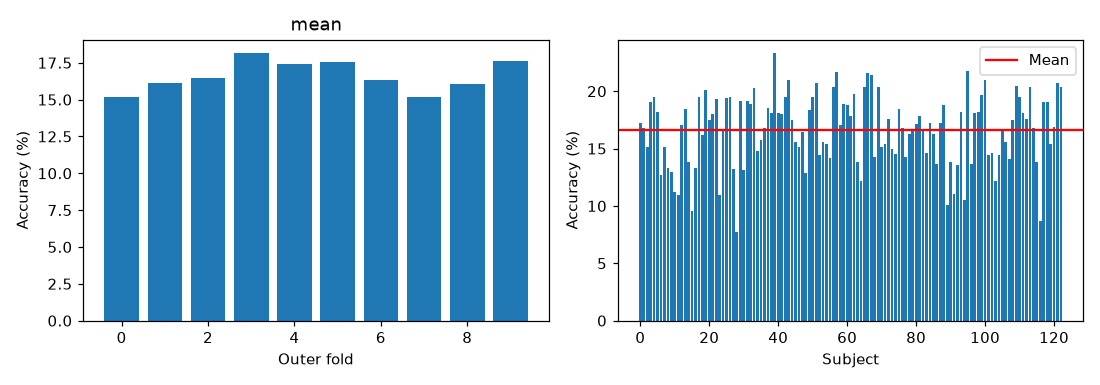

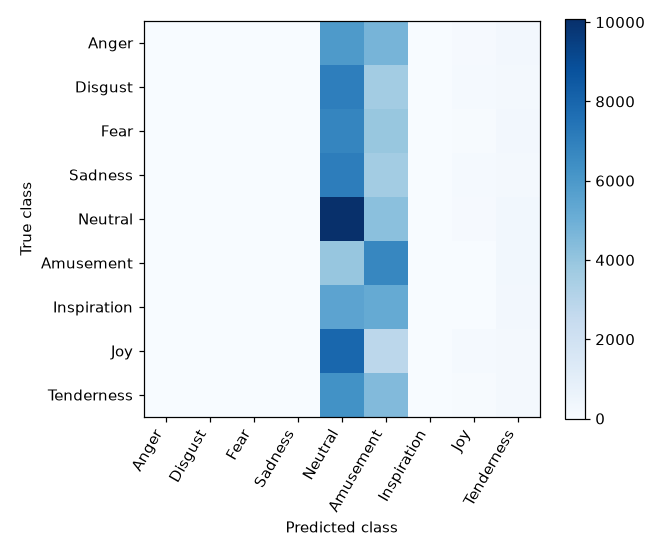

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
fold_scores = [f['test']['accuracy'] * 100 for f in results['folds']]
axes[0].bar(np.arange(10), fold_scores)
axes[0].set(xlabel='Outer fold', ylabel='Accuracy (%)', title=variant)
axes[1].bar(subject_results['subject'], subject_results['accuracy'] * 100)
axes[1].axhline(results['accuracy'] * 100, color='red', label='Mean')
axes[1].set(xlabel='Subject', ylabel='Accuracy (%)')
axes[1].legend()
fig.tight_layout()
plt.show()

matrix = np.bincount((targets * 9 + predictions).ravel(), minlength=81).reshape(9, 9)
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(matrix, cmap='Blues')
ax.set(xticks=np.arange(9), yticks=np.arange(9), xlabel='Predicted class', ylabel='True class')
ax.set_xticklabels(class_names, rotation=60, ha='right')
ax.set_yticklabels(class_names)
fig.colorbar(image, ax=ax)
fig.tight_layout()
plt.show()
